# Actividad 1. Modelado predictivo de actividad hemolítica mediante aprendizaje automático

# Samuel Salazar Diaz

## Parte 2: Conversión de secuencias a SMILES (pyPept) y cálculo de descriptores (Mordred)

**Entrada:** CSV generados en la Parte 1, en `Act1_PSU/datos_procesados/` (`HemoPI-X_train.csv` y `HemoPI-X_validation.csv`).

**Metodología**
1. Instala pyPept y Mordred y carga los datos curados.
2. Convierte cada secuencia aminoacídica a SMILES con **pyPept** (secuencia → BILN → molécula RDKit → SMILES).
3. Calcula con **Mordred** un subconjunto seleccionado de 45 descriptores 2D para cada SMILES.
4. Limpia los descriptores: valores faltantes, constantes y alta correlación (|r| > 0,9).
5. Guarda las tablas finales en `Act1_PSU/descriptores/` para la Parte 3 (modelos).

**Regla metodológica clave:** todas las decisiones de limpieza (qué descriptores se eliminan, medianas de imputación) se calculan **solo con el conjunto de entrenamiento** y se aplican después, tal cual, a validación. Así la validación externa permanece independiente y no hay fuga de información.

**Referencias:**
- Ochoa, R., Brown, J. B., & Fox, T. (2023). pyPept: a python library to generate atomistic 2D and 3D representations of peptides. *Journal of Cheminformatics, 15*, 79. https://doi.org/10.1186/s13321-023-00748-2
- Moriwaki, H., Tian, Y.-S., Kawashita, N., & Takagi, T. (2018). Mordred: a molecular descriptor calculator. *Journal of Cheminformatics, 10*, 4. https://doi.org/10.1186/s13321-018-0258-y

## 1. Preparación del entorno

- **pyPept** no está en PyPI: se instala directamente desde el repositorio oficial de GitHub (Boehringer Ingelheim).
- **Mordred** original no funciona con versiones recientes de NumPy. Se usa `mordredcommunity`, un fork mantenido que se importa igual (`import mordred`).

Si Colab pide reiniciar el entorno tras la instalación, reinícialo y continúa desde la celda de importaciones.

In [1]:
!pip -q install mordredcommunity
!pip -q install git+https://github.com/Boehringer-Ingelheim/pyPept.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os
import functools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from rdkit import Chem
from rdkit.Chem import Draw, PandasTools

# pyPept: clases para pasar de secuencia a molécula
import pyPept.sequence as ppseq
from pyPept.sequence import Sequence, SequenceConstants, correct_pdb_atoms
from pyPept.molecule import Molecule

# Mordred: calculadora de descriptores moleculares
from mordred import Calculator, descriptors

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
print('pandas', pd.__version__, '| numpy', np.__version__)

pandas 2.2.3 | numpy 2.4.6


In [3]:
# Montamos Drive (si ya está montado, no pasa nada)
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = '/content/drive/MyDrive/Act1_PSU'
IN_DIR   = f'{BASE_DIR}/datos_procesados'   # salida de la Parte 1
OUT_DIR  = f'{BASE_DIR}/descriptores'       # salida de esta Parte 2
os.makedirs(OUT_DIR, exist_ok=True)

DATASETS = ['HemoPI-1', 'HemoPI-2', 'HemoPI-3']

# Parámetros del preprocesamiento de descriptores
UMBRAL_CORR = 0.9    # se elimina un descriptor si |r| > 0,9 con otro ya conservado
UMBRAL_NAN  = 0.05   # se elimina un descriptor si más del 5 % de sus valores (en entrenamiento) no se pudo calcular
NPROC = os.cpu_count() or 1   # núcleos para paralelizar Mordred
print('Núcleos disponibles:', NPROC)

Mounted at /content/drive
Núcleos disponibles: 2


In [4]:
# Cargamos los CSV de la Parte 1: un DataFrame por dataset y partición
meta = {}   # claves: (dataset, 'train' | 'valid')
for ds in DATASETS:
    meta[(ds, 'train')] = pd.read_csv(f'{IN_DIR}/{ds}_train.csv')
    meta[(ds, 'valid')] = pd.read_csv(f'{IN_DIR}/{ds}_validation.csv')

# Resumen de lo cargado
resumen = pd.DataFrame({f'{ds} {sp}': [len(d), d['label'].sum()]
                        for (ds, sp), d in meta.items()}, index=['n_peptidos', 'n_clase1']).T
resumen

,n_peptidos,n_clase1
HemoPI-1 train,884,442
HemoPI-1 valid,220,110
HemoPI-2 train,812,442
HemoPI-2 valid,202,110
HemoPI-3 train,1298,708
HemoPI-3 valid,325,177


## 2. Conversión de secuencias a SMILES con pyPept

pyPept no lee directamente una secuencia tipo `GLFDIVKK`: trabaja con **BILN** (*Boehringer Ingelheim Line Notation*), que separa los monómeros con guiones (`G-L-F-D-I-V-K-K`). Como nuestras secuencias son de aminoácidos naturales, basta con insertar un guion entre letras. Después pyPept construye la molécula completa (enlaces peptídicos incluidos) como objeto RDKit, de donde se obtiene el SMILES.

### 2.1 Parche de compatibilidad con pandas

La función interna `get_monomer_info` de pyPept asigna una lista dentro de una celda de un DataFrame, algo que falla en versiones recientes de pandas (`ValueError: Must have equal len keys...`). La reescribimos con la misma lógica pero compatible con cualquier versión y con caché, de modo que el diccionario de monómeros se lea del disco una sola vez y no en cada péptido. No modifica el resultado químico.

In [5]:
@functools.lru_cache(maxsize=None)   # el archivo de monómeros se lee una sola vez
def get_monomer_info_parcheada(path):
    """Misma lógica que pyPept.sequence.get_monomer_info, compatible con pandas >= 3."""
    df_group = PandasTools.LoadSDF(path)
    for group in ['m_Rgroups', 'm_RgroupIdx', 'm_attachmentPointIdx']:
        valores = []
        for celda in df_group[group]:
            partes = str(celda).split(SequenceConstants.csv_separator)
            if group == 'm_Rgroups':
                valores.append([None if v == 'None' else v for v in partes])
            else:
                valores.append([None if v == 'None' else int(v) for v in partes])
        df_group[group] = pd.Series(valores, index=df_group.index, dtype=object)
    df_group = df_group.set_index('symbol')
    return df_group.rename(columns={'ROMol': 'm_romol'})

# Sustituimos la función original por la parcheada
ppseq.get_monomer_info = get_monomer_info_parcheada

### 2.2 Función secuencia → SMILES y prueba con un péptido

Péptido  : peptide_nm_1
Secuencia: TKTTRNSPDSISIP
SMILES   : CC[C@H](C)[C@H](NC(=O)[C@H](CO)NC(=O)[C@H](CC(=O)O)NC(=O)[C@@H]1CCCN1C(=O)[C@H](CO)NC(=O)[C@H](CC(N)=O)NC(=O)[C@H](CCCNC(=N)N)NC(=O)[C@@H](NC(=O)[C@@H](NC(=O)[C@H](CCCCN)NC(=O)[C@@H](N)[C@@H](C)O)[C@@H](C)O)[C@@H](C)O)C(=O)N[C@@H](CO)C(=O)N[C@H](C(=O)N1CCC[C@H]1C(=O)O)[C@@H](C)CC


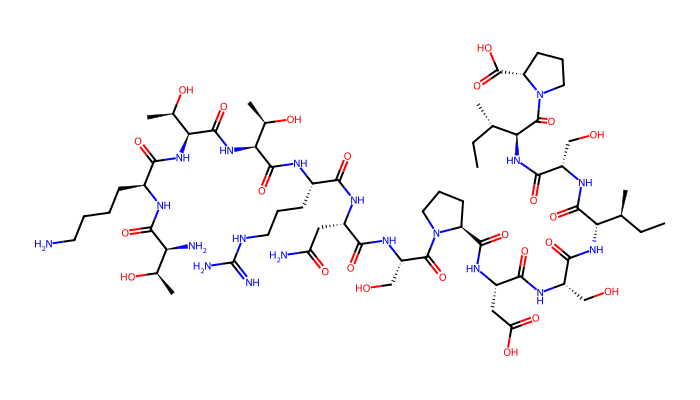

In [6]:
def secuencia_a_smiles(secuencia):
    """
    Convierte una secuencia de aminoácidos (código de 1 letra) en un SMILES.
    Pasos: secuencia -> BILN -> Sequence (pyPept) -> Molecule -> RDKit Mol -> SMILES
    """
    biln = '-'.join(secuencia)                      # 'GLF' -> 'G-L-F'
    seq = correct_pdb_atoms(Sequence(biln))         # construye la secuencia y corrige nombres de átomos
    romol = Molecule(seq).get_molecule(fmt='ROMol') # molécula RDKit con los enlaces peptídicos
    return Chem.MolToSmiles(romol)

# Prueba con el primer péptido del dataset HemoPI-1 (entrenamiento)
ejemplo = meta[('HemoPI-1', 'train')].iloc[0]
smi_ej = secuencia_a_smiles(ejemplo['sequence'])
mol_ej = Chem.MolFromSmiles(smi_ej)

print('Péptido  :', ejemplo['peptide_id'])
print('Secuencia:', ejemplo['sequence'])
print('SMILES   :', smi_ej)
Draw.MolToImage(mol_ej, size=(700, 400))

### 2.3 Convertir todas las secuencias

Para no repetir trabajo, se convierten solo las secuencias **únicas** de todos los datasets y particiones. Si alguna secuencia falla se registra y se excluye (se informa cuántas).

In [7]:
# Secuencias únicas de todos los conjuntos
todas = pd.concat([d['sequence'] for d in meta.values()]).unique()
print('Secuencias únicas a convertir:', len(todas))

dic_smiles, fallos = {}, {}
for s in tqdm(todas, desc='Secuencia -> SMILES'):
    try:
        smi = secuencia_a_smiles(s)
        # Comprobamos que RDKit puede volver a leer el SMILES generado
        if Chem.MolFromSmiles(smi) is None:
            raise ValueError('SMILES no válido para RDKit')
        dic_smiles[s] = smi
    except Exception as e:
        fallos[s] = repr(e)[:120]

print(f'Convertidas: {len(dic_smiles)} | Fallidas: {len(fallos)}')
if fallos:
    display(pd.Series(fallos, name='error').head(10))

Secuencias únicas a convertir: 2275


Secuencia -> SMILES:   0%|          | 0/2275 [00:00<?, ?it/s]

Convertidas: 2275 | Fallidas: 0


In [8]:
# Añadimos la columna 'smiles' a cada tabla y descartamos las secuencias que fallaron
for clave, d in meta.items():
    d['smiles'] = d['sequence'].map(dic_smiles)
    n_antes = len(d)
    meta[clave] = d.dropna(subset=['smiles']).reset_index(drop=True)
    if len(meta[clave]) < n_antes:
        print(f'{clave}: se descartaron {n_antes - len(meta[clave])} péptidos sin SMILES')

# Guardamos las tablas con SMILES (útil para el informe y para reutilizar sin repetir la conversión)
for ds in DATASETS:
    meta[(ds, 'train')].to_csv(f'{OUT_DIR}/{ds}_train_smiles.csv', index=False)
    meta[(ds, 'valid')].to_csv(f'{OUT_DIR}/{ds}_validation_smiles.csv', index=False)

meta[('HemoPI-1', 'train')][['peptide_id', 'sequence', 'smiles', 'label']].head()

,peptide_id,sequence,smiles,label
0,peptide_nm_1,TKTTRNSPDSISIP,CC[C@H](C)[C@H](NC(=O)[C@H](CO)NC(=O)[C@H](CC(...,0
1,peptide_nm_2,QRHPFKPKLHHID,CC[C@H](C)[C@H](NC(=O)[C@H](Cc1c[nH]cn1)NC(=O)...,0
2,peptide_nm_3,KIPVVAAIHGACLGGGLELALACHQRV,CC[C@H](C)[C@H](NC(=O)[C@H](C)NC(=O)[C@H](C)NC...,0
3,peptide_nm_4,NELPEPEQDNGGATESVKEQEMKW,CSCC[C@H](NC(=O)[C@H](CCC(=O)O)NC(=O)[C@H](CCC...,0
4,peptide_nm_5,YQIDQLSKMTYKNKSLNIHDLTA,CC[C@H](C)[C@H](NC(=O)[C@H](CC(N)=O)NC(=O)[C@H...,0


## 3. Descriptores fisicoquímicos con Mordred

Mordred puede calcular **1613 descriptores 2D** a partir de un SMILES (los 3D requieren coordenadas y conformeros, que no tenemos). Son valores **calculados** a partir de la estructura química, no predichos por un modelo; algunos, como `SLogP`, son estimaciones basadas en contribuciones atómicas.

En este trabajo se usan **45 descriptores de Mordred**, agrupados en las siguientes categorías:

| Categoría | Descriptores usados | Qué describen | Por qué se seleccionaron (relevancia posible) |
|---|---|---|---|
| **Tamaño y composición** (17) | `MW`, `nAtom`, `nHeavyAtom`, `nC`, `nN`, `nO`, `nS`, `nH`, `nHetero`, `nBonds`, `nRot`, `nRing`, `nARing`, `nAromAtom`, `nAromBond`, `Vabc`, `VMcGowan` | Masa, número de átomos por elemento, enlaces, enlaces rotables (flexibilidad), anillos y aromaticidad, y volumen molecular | Reflejan la longitud del péptido y su composición (p. ej. residuos aromáticos); el tamaño puede influir en cómo interactúa con la membrana |
| **Lipofilia y refractividad** (5) | `SLogP`, `SMR`, `SlogP_VSA2`, `SlogP_VSA5`, `FilterItLogS` | Hidrofobicidad estimada (Crippen), refractividad molar, superficie ponderada por lipofilia y solubilidad estimada | La hidrofobicidad se relaciona con la capacidad de insertarse en la bicapa lipídica del eritrocito |
| **Polaridad y puentes de hidrógeno** (5) | `nHBDon`, `nHBAcc`, `TopoPSA`, `TopoPSA(NO)`, `LabuteASA` | Donadores y aceptores de puentes de H, superficie polar topológica y área superficial aproximada | Describen la polaridad y la posible interacción con las cabezas polares de los lípidos y con el agua |
| **Ionizables y carga parcial** (5) | `nAcid`, `nBase`, `PEOE_VSA1`, `PEOE_VSA6`, `PEOE_VSA13` | Grupos ácidos y básicos, y superficie ponderada por carga parcial | Aproximan el balance de carga del péptido (por ejemplo, el carácter catiónico) |
| **Topología y forma** (10) | `BalabanJ`, `BertzCT`, `Zagreb1`, `WPath`, `Kier1`, `Kier3`, `Radius`, `Diameter`, `fragCpx`, `FCSP3` | Ramificación, compacidad, forma y complejidad del grafo molecular | Resumen de la forma y la complejidad estructural sin necesidad de coordenadas 3D |
| **Polarizabilidad** (3) | `apol`, `bpol`, `AMW` | Polarizabilidad atómica y de enlace, y masa atómica media | Describen la distribución electrónica y la masa media por átomo |

> **Nota:** estos descriptores se seleccionaron a criterio porque, al intentar calcular todos los descriptores de Mordred, el proceso resultó muy lento y pesado. Se eligieron los que pueden ser más relevantes según su significado fisicoquímico. La columna de relevancia es una **hipótesis de trabajo** para la interpretación posterior, no un resultado: habrá que contrastarla con la importancia real de cada descriptor en los modelos.

**Limitaciones:** los descriptores 2D no codifican el orden de la secuencia ni la estructura secundaria (hélice, anfipaticidad). Además, en péptidos grandes muchos descriptores de tamaño crecen juntos y quedan muy correlacionados entre sí; por eso el filtrado por correlación elimina una parte importante.

In [9]:
# Descriptores obligatorios (equivalentes en Mordred de los usados en clase):
#   MW     ~ MolWt          (masa molecular)
#   SLogP  ~ MolLogP        (lipofilia estimada, Crippen)
#   nHBDon ~ NumHDonors     (donadores de puentes de H)
#   nHBAcc ~ NumHAcceptors  (aceptores de puentes de H)
OBLIGATORIOS = ['MW', 'SLogP', 'nHBDon', 'nHBAcc']

# Selección de descriptores de Mordred por categoría (45 en total, máximo permitido: 50)
SELECCION = {
    'Tamaño y composición': ['MW', 'nAtom', 'nHeavyAtom', 'nC', 'nN', 'nO', 'nS', 'nH', 'nHetero',
                             'nBonds', 'nRot', 'nRing', 'nARing', 'nAromAtom', 'nAromBond',
                             'Vabc', 'VMcGowan'],   # Vabc = volumen de van der Waals; VMcGowan = volumen de McGowan
    'Lipofilia y refractividad': ['SLogP', 'SMR', 'SlogP_VSA2', 'SlogP_VSA5', 'FilterItLogS'],
    'Polaridad y puentes de H': ['nHBDon', 'nHBAcc', 'TopoPSA', 'TopoPSA(NO)', 'LabuteASA'],
    'Ionizables y carga parcial': ['nAcid', 'nBase', 'PEOE_VSA1', 'PEOE_VSA6', 'PEOE_VSA13'],
    'Topología y forma': ['BalabanJ', 'BertzCT', 'Zagreb1', 'WPath', 'Kier1', 'Kier3',
                          'Radius', 'Diameter', 'fragCpx', 'FCSP3'],
    'Polarizabilidad': ['apol', 'bpol', 'AMW'],
}
nombres = [n for lista in SELECCION.values() for n in lista]

# Calculadora de Mordred que solo contiene los descriptores elegidos
# (se parte de la lista completa de 2D y se registran solo los seleccionados)
calc_completa = Calculator(descriptors, ignore_3D=True)
calc = Calculator()
for d in calc_completa.descriptors:
    if str(d) in nombres:
        calc.register(d)

faltan = set(nombres) - {str(d) for d in calc.descriptors}
print('Descriptores Mordred seleccionados:', len(calc.descriptors), '| no encontrados:', faltan if faltan else 'ninguno')
assert len(calc.descriptors) <= 50, 'Se superó el máximo de 50 descriptores'
assert set(OBLIGATORIOS) <= set(nombres), 'Falta algún descriptor obligatorio'

Descriptores Mordred seleccionados: 45 | no encontrados: ninguno


### 3.1 Calcular los descriptores

Con solo 45 descriptores el cálculo es rápido. Aun así, el resultado **crudo** se guarda en Drive: si la sesión se desconecta, al volver a ejecutar la celda se leen los archivos ya calculados en lugar de recalcular.

Mordred devuelve objetos de error (`Error`) cuando un descriptor no se puede calcular para una molécula; `pd.to_numeric(..., errors='coerce')` los convierte en `NaN` para poder tratarlos.

In [10]:
def calcular_descriptores(df, ruta_cache):
    """Calcula los descriptores de Mordred seleccionados para df['smiles']; usa/crea una caché en Drive."""
    if os.path.exists(ruta_cache):
        crudo = pd.read_csv(ruta_cache)
        # Seguridad: la caché debe corresponder a los mismos péptidos, en el mismo orden y con las mismas columnas
        if list(crudo['peptide_id']) == list(df['peptide_id']) and set(nombres) <= set(crudo.columns):
            print('  (cargado desde caché)')
            return crudo.drop(columns='peptide_id')
        print('  (la caché no coincide; se recalcula)')

    mols = [Chem.MolFromSmiles(s) for s in df['smiles']]
    desc = calc.pandas(mols, nproc=1, nmols=len(mols), quiet=True)
    desc = desc.apply(pd.to_numeric, errors='coerce').astype(float)   # Error -> NaN; bool/int -> float
    desc.columns = [str(c) for c in desc.columns]

    guardar = desc.copy()
    guardar.insert(0, 'peptide_id', df['peptide_id'].values)
    guardar.to_csv(ruta_cache, index=False)
    return desc

raw = {}   # descriptores crudos por (dataset, partición)
for ds in DATASETS:
    for sp in ['train', 'valid']:
        print(f'{ds} | {sp} | {len(meta[(ds, sp)])} péptidos')
        raw[(ds, sp)] = calcular_descriptores(meta[(ds, sp)], f'{OUT_DIR}/{ds}_{sp}_descriptores_crudo.csv')

print('Dimensiones (péptidos x descriptores):', {k: v.shape for k, v in raw.items()})

HemoPI-1 | train | 884 péptidos
HemoPI-1 | valid | 220 péptidos
HemoPI-2 | train | 812 péptidos
HemoPI-2 | valid | 202 péptidos
HemoPI-3 | train | 1298 péptidos
HemoPI-3 | valid | 325 péptidos
Dimensiones (péptidos x descriptores): {('HemoPI-1', 'train'): (884, 45), ('HemoPI-1', 'valid'): (220, 45), ('HemoPI-2', 'train'): (812, 45), ('HemoPI-2', 'valid'): (202, 45), ('HemoPI-3', 'train'): (1298, 45), ('HemoPI-3', 'valid'): (325, 45)}


### 3.2 Exploración de los descriptores obligatorios

Distribución por clase de los cuatro descriptores básicos de la práctica de clase (masa, lipofilia, donadores y aceptores de H), en su versión de Mordred: `MW`, `SLogP`, `nHBDon` y `nHBAcc`.

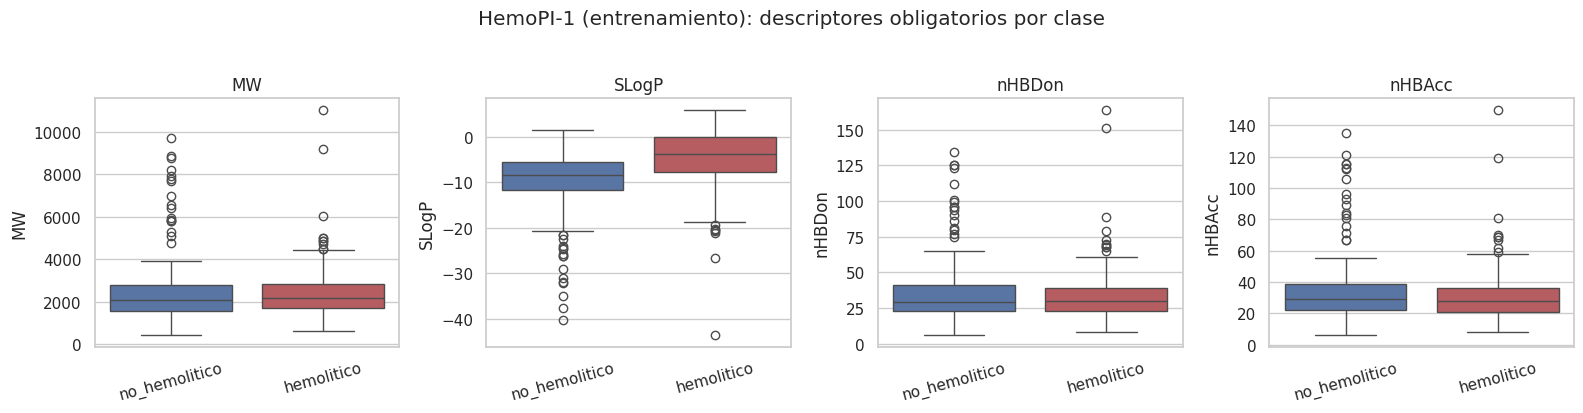

,MW,SLogP,nHBDon,nHBAcc
activity,,,,
hemolitico,2171.35,-3.85,30.0,28.0
no_hemolitico,2072.59,-8.31,29.0,29.0


In [11]:
# Distribución por clase de los descriptores obligatorios (HemoPI-1, entrenamiento)
d1 = meta[('HemoPI-1', 'train')]
tabla = pd.concat([d1[['activity']].reset_index(drop=True), raw[('HemoPI-1', 'train')][OBLIGATORIOS]], axis=1)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, OBLIGATORIOS):
    sns.boxplot(data=tabla, x='activity', y=col, ax=ax, palette=['#4C72B0', '#C44E52'])
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=15)
plt.suptitle('HemoPI-1 (entrenamiento): descriptores obligatorios por clase', y=1.03)
plt.tight_layout()
plt.show()

tabla.groupby('activity')[OBLIGATORIOS].median().round(2)

## 4. Limpieza de descriptores (ajustada solo con entrenamiento)

Se aplica a **cada dataset por separado**, en este orden:

1. **Valores infinitos → NaN.**
2. **Descriptores con demasiados valores faltantes** (> `UMBRAL_NAN` en entrenamiento): se eliminan. Los NaN restantes se imputan con la **mediana de entrenamiento**.
3. **Descriptores constantes** (un único valor en entrenamiento): no aportan información; se eliminan.
4. **Alta correlación (|r| de Pearson > 0,9):** los descriptores obligatorios (`OBLIGATORIOS`) se conservan siempre. El resto se recorre en orden y se conserva solo si su correlación con **todos** los ya conservados es ≤ 0,9.

Las listas de descriptores eliminados y las medianas se calculan en entrenamiento y se reutilizan en validación.

In [12]:
def limpiar_descriptores(X_tr, X_va, umbral_nan=UMBRAL_NAN, umbral_corr=UMBRAL_CORR, protegidos=()):
    """
    Ajusta la limpieza con X_tr (entrenamiento) y la aplica a X_va (validación).
    'protegidos': descriptores que se conservan siempre en el filtro de correlación
    (los OBLIGATORIOS: MW, SLogP, nHBDon, nHBAcc). Los demás se descartan
    si correlacionan > umbral_corr con alguno ya conservado.
    """
    conteo = {'1. Descriptores iniciales': X_tr.shape[1]}

    # 1) Infinitos -> NaN
    X_tr = X_tr.replace([np.inf, -np.inf], np.nan)
    X_va = X_va.replace([np.inf, -np.inf], np.nan)

    # 2) Demasiados NaN en entrenamiento -> se eliminan; los demás se imputan con la mediana de entrenamiento
    prop_nan = X_tr.isna().mean()
    cols = prop_nan[prop_nan <= umbral_nan].index
    X_tr, X_va = X_tr[cols], X_va[cols]
    conteo[f'2. Tras eliminar NaN > {umbral_nan:.0%}'] = len(cols)

    medianas = X_tr.median()
    X_tr = X_tr.fillna(medianas)
    X_va = X_va.fillna(medianas)

    # 3) Constantes en entrenamiento
    cols = X_tr.columns[X_tr.nunique() > 1]
    X_tr, X_va = X_tr[cols], X_va[cols]
    conteo['3. Tras eliminar constantes'] = len(cols)

    # 4) Correlación alta: los protegidos entran primero y siempre se conservan;
    #    el resto se conserva solo si |r| <= umbral con todos los ya conservados
    corr = X_tr.corr(method='pearson').abs().values
    idx_prot = [j for j, c in enumerate(X_tr.columns) if c in protegidos]
    conservar = list(idx_prot)
    for j in range(corr.shape[0]):
        if j in idx_prot:
            continue
        if all(corr[j, k] <= umbral_corr for k in conservar):
            conservar.append(j)
    cols = X_tr.columns[sorted(conservar)]
    X_tr, X_va = X_tr[cols], X_va[cols]
    conteo[f'4. Tras filtro |r| > {umbral_corr}'] = len(cols)

    return X_tr, X_va, conteo

limpio, conteos = {}, {}
for ds in DATASETS:
    Xtr, Xva, conteo = limpiar_descriptores(raw[(ds, 'train')], raw[(ds, 'valid')],
                                            protegidos=OBLIGATORIOS)
    limpio[(ds, 'train')], limpio[(ds, 'valid')] = Xtr, Xva
    conteos[ds] = conteo

resumen_desc = pd.DataFrame(conteos)
resumen_desc

,HemoPI-1,HemoPI-2,HemoPI-3
1. Descriptores iniciales,45,45,45
2. Tras eliminar NaN > 5%,45,45,45
3. Tras eliminar constantes,44,44,44
4. Tras filtro |r| > 0.9,16,17,17


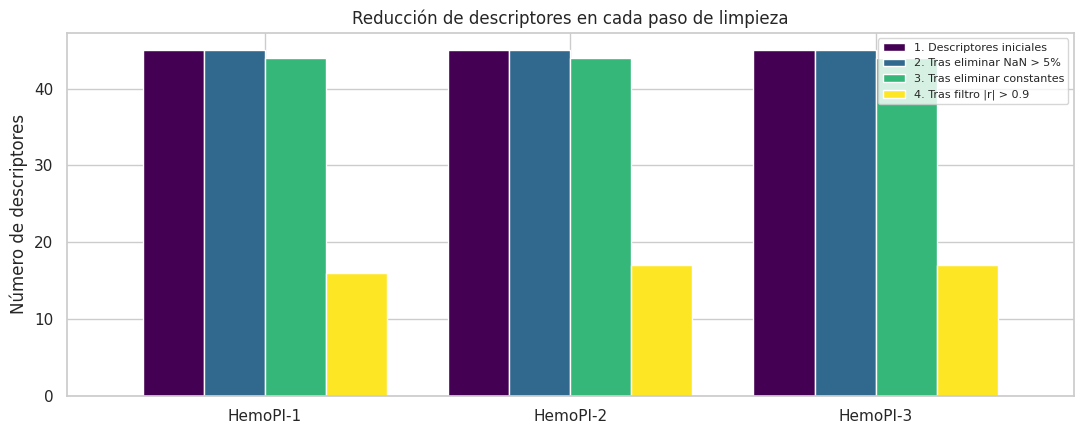

In [13]:
# Embudo de filtrado: cuántos descriptores quedan en cada paso y dataset
ax = resumen_desc.T.plot(kind='bar', figsize=(11, 4.5), width=0.8, colormap='viridis')
ax.set_ylabel('Número de descriptores')
ax.set_xlabel('')
ax.set_title('Reducción de descriptores en cada paso de limpieza')
ax.legend(loc='upper right', fontsize=8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 4.1 Efecto del filtro de correlación

Matriz de correlación de los descriptores interpretables **antes** del filtro (HemoPI-1, entrenamiento). Los que aparecen muy correlacionados entre sí son los que el filtro agrupa: se conserva solo uno de cada grupo, y la tabla indica cuáles quedaron.

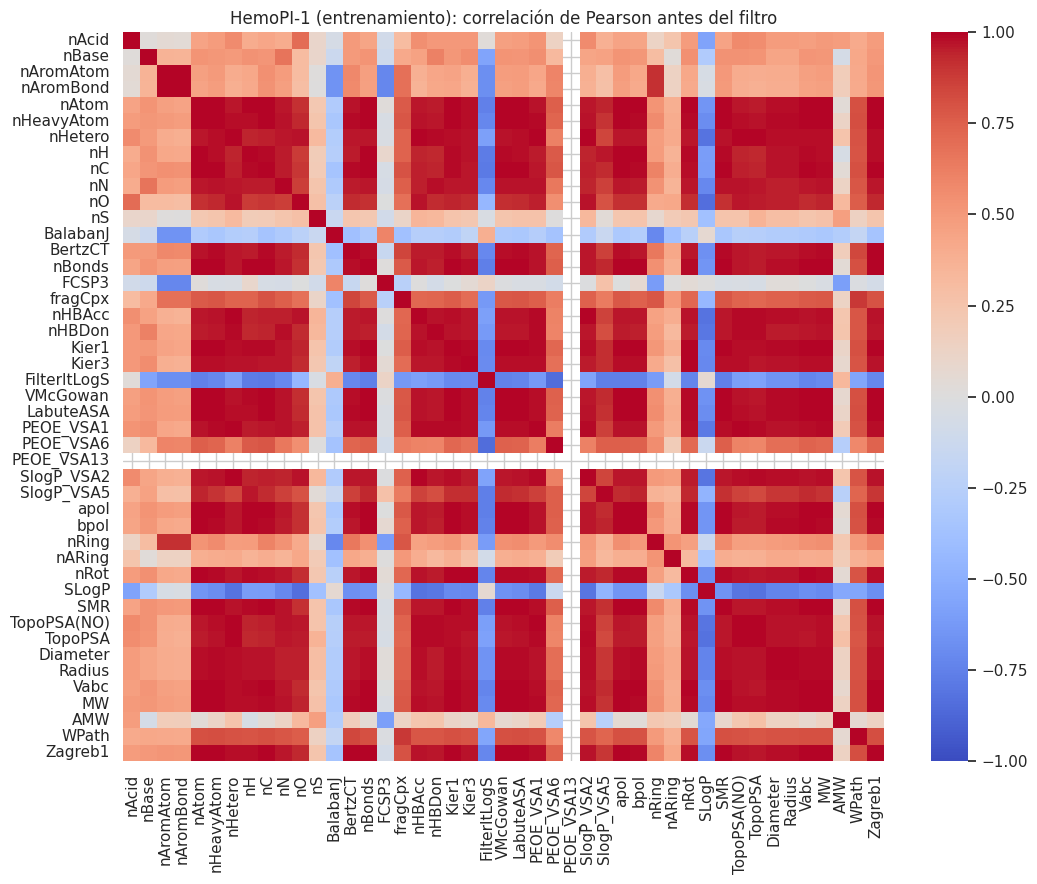

,conservado
nAcid,True
nBase,True
nAromAtom,True
nAromBond,False
nAtom,False
nHeavyAtom,False
nHetero,False
nH,False
nC,False
nN,False


In [14]:
ds0 = 'HemoPI-1'
X0 = raw[(ds0, 'train')]

# Matriz de correlación de los descriptores seleccionados ANTES del filtro (sin anotar números: son 45 variables)
plt.figure(figsize=(11, 9))
sns.heatmap(X0.corr(), cmap='coolwarm', center=0, vmin=-1, vmax=1, xticklabels=True, yticklabels=True)
plt.title(f'{ds0} (entrenamiento): correlación de Pearson antes del filtro')
plt.tight_layout()
plt.show()

# ¿Cuáles sobrevivieron al filtro |r| > 0,9? (los obligatorios están protegidos y siempre se conservan)
pd.DataFrame({'conservado': [c in limpio[(ds0, 'train')].columns for c in X0.columns]}, index=X0.columns)

## 5. Guardar las tablas finales

Cada archivo contiene `peptide_id`, `sequence`, `smiles`, `label` y los descriptores seleccionados. Las columnas de descriptores son **las mismas** en entrenamiento y validación de un mismo dataset, requisito para que el modelo entrenado pueda predecir sobre validación.

In [15]:
filas_resumen = []
for ds in DATASETS:
    for sp, nombre in [('train', 'train'), ('valid', 'validation')]:
        identif = meta[(ds, sp)][['peptide_id', 'sequence', 'smiles', 'label']].reset_index(drop=True)
        final = pd.concat([identif, limpio[(ds, sp)].reset_index(drop=True)], axis=1)
        final.to_csv(f'{OUT_DIR}/{ds}_{nombre}_descriptores.csv', index=False)
        filas_resumen.append({'dataset': ds, 'particion': nombre, 'n_peptidos': final.shape[0],
                              'n_descriptores': limpio[(ds, sp)].shape[1],
                              'n_hemoliticos(clase1)': int(final['label'].sum())})

    # Lista de descriptores seleccionados (para documentar y reproducir)
    with open(f'{OUT_DIR}/{ds}_descriptores_seleccionados.txt', 'w') as f:
        f.write('\n'.join(limpio[(ds, 'train')].columns))

resumen_desc.to_csv(f'{OUT_DIR}/resumen_filtrado_descriptores.csv')
pd.DataFrame(filas_resumen)

,dataset,particion,n_peptidos,n_descriptores,n_hemoliticos(clase1)
0,HemoPI-1,train,884,16,442
1,HemoPI-1,validation,220,16,110
2,HemoPI-2,train,812,17,442
3,HemoPI-2,validation,202,17,110
4,HemoPI-3,train,1298,17,708
5,HemoPI-3,validation,325,17,177


In [16]:
# Verificación final: mismas columnas en entrenamiento y validación, sin NaN
for ds in DATASETS:
    ok_cols = list(limpio[(ds, 'train')].columns) == list(limpio[(ds, 'valid')].columns)
    n_nan = int(limpio[(ds, 'train')].isna().sum().sum() + limpio[(ds, 'valid')].isna().sum().sum())
    print(f'{ds}: columnas idénticas = {ok_cols} | NaN totales = {n_nan}')
print('Archivos en', OUT_DIR)
print(sorted(os.listdir(OUT_DIR)))

HemoPI-1: columnas idénticas = True | NaN totales = 0
HemoPI-2: columnas idénticas = True | NaN totales = 0
HemoPI-3: columnas idénticas = True | NaN totales = 0
Archivos en /content/drive/MyDrive/Act1_PSU/descriptores
['HemoPI-1_descriptores_seleccionados.txt', 'HemoPI-1_train_descriptores.csv', 'HemoPI-1_train_descriptores_crudo.csv', 'HemoPI-1_train_smiles.csv', 'HemoPI-1_valid_descriptores_crudo.csv', 'HemoPI-1_validation_descriptores.csv', 'HemoPI-1_validation_smiles.csv', 'HemoPI-2_descriptores_seleccionados.txt', 'HemoPI-2_train_descriptores.csv', 'HemoPI-2_train_descriptores_crudo.csv', 'HemoPI-2_train_smiles.csv', 'HemoPI-2_valid_descriptores_crudo.csv', 'HemoPI-2_validation_descriptores.csv', 'HemoPI-2_validation_smiles.csv', 'HemoPI-3_descriptores_seleccionados.txt', 'HemoPI-3_train_descriptores.csv', 'HemoPI-3_train_descriptores_crudo.csv', 'HemoPI-3_train_smiles.csv', 'HemoPI-3_valid_descriptores_crudo.csv', 'HemoPI-3_validation_descriptores.csv', 'HemoPI-3_validation_smil

## Siguiente paso

- **Selección a criterio:** se usaron 45 descriptores de Mordred elegidos por su significado fisicoquímico (ver tabla de la sección 3), porque calcular todos era muy lento. Conviene mencionarlo como limitación.
- **Descriptores solo 2D**: no capturan el orden de la secuencia ni la estructura secundaria.
- **Filtro de correlación**: los descriptores de tamaño crecen juntos con la longitud del péptido, así que el filtro |r| > 0,9 puede dejar un número reducido de descriptores. Revisa la tabla `resumen_desc`.
- **PCA (Parte 3)**: escalar con `StandardScaler` y ajustar PCA solo con entrenamiento, dentro de un `Pipeline`. Los componentes no se interpretan químicamente; para la interpretación biológica de los descriptores (Criterio 5) calcula la importancia sobre los descriptores originales.
- **Escalado**: regresión logística y SVM lo necesitan; Random Forest y Gradient Boosting no.
- **Parte 3**: leer `HemoPI-X_train_descriptores.csv` y `HemoPI-X_validation_descriptores.csv`; usar `label` como variable objetivo.